# Notebook 16: the same question, a different answer at temperature 0

Temperature 0 means greedy decoding: at every step the model takes the single most likely next token, with no sampling. It is natural to expect the same prompt to give the same answer every time. This notebook shows when that fails, how large the effect is on a laptop CPU, and how to keep it from changing a decision.

The Thinking Machines post "Defeating Nondeterminism in LLM Inference" (https://thinkingmachines.ai/blog/defeating-nondeterminism-in-llm-inference/, a company blog post, not peer reviewed) reports that Qwen3-235B-A22B-Instruct-2507, asked "Tell me about Richard Feynman" 1,000 times at temperature 0, produced 80 distinct 1,000-token answers, the first split coming at token 103. The post traces this to batching: a server processes your request together with other users' requests, several operations add numbers in an order that depends on the batch size, and floating-point addition gives slightly different results when the order changes. The post measures no commercial API itself; it cites earlier discussion for that.

We cannot run a 235B model here, and a laptop answering one request at a time never changes its batch. So we change the serving conditions ourselves: the same prompts alone, alone again, and inside batches with other prompts. The model is Qwen2.5-0.5B-Instruct on this CPU, in float32 (full precision) and bfloat16 (half precision, the format most large models are served in). Looping one prompt on this machine showed nothing in float32 (0 of 10 answers differed in an earlier draft of this notebook), which is why the conditions below are varied on purpose.

On a loaded laptop CPU the whole notebook takes about two hours, and bfloat16 passes are slow here (tens of seconds each), so every long cell prints a line as each step ends.

In [1]:
import json, time, re
from collections import Counter
from pathlib import Path
import numpy as np, torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
import meridian as m

torch.set_num_threads(3)
NAME = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(NAME, local_files_only=True, padding_side="left")
def load(dtype): return AutoModelForCausalLM.from_pretrained(NAME, dtype=dtype, local_files_only=True, attn_implementation="eager").eval()
lm = load(torch.float32)      # full precision
lm16 = load(torch.bfloat16)   # half precision, the format most large models are served in

te = m.load("test")
chat = lambda user: tok.apply_chat_template([{"role": "user", "content": user}], add_generation_prompt=True, tokenize=False)
reply_prompt = lambda msg: chat(f"Write a two-sentence reply to this customer message from a travel company.\n\nMessage: {msg}")

def generate(model, prompts, n_new, **kw):
    """Generated token ids for each prompt, cut at the end-of-text token. Prompts are left-padded to one length."""
    enc = tok(prompts, return_tensors="pt", padding=True)
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=n_new, pad_token_id=tok.pad_token_id, top_k=None, **kw)
    res = []
    for row in out[:, enc.input_ids.shape[1]:].tolist():
        res.append(row[:row.index(tok.eos_token_id)] if tok.eos_token_id in row else row)
    return res

ROUTES = m.ROUTES
sys_prompt = "You route customer messages for a travel company. Reply with only the name of the team, exactly as written, from this list: " + ", ".join(ROUTES) + "."
label_prompt = lambda msg: tok.apply_chat_template([{"role": "system", "content": sys_prompt}, {"role": "user", "content": msg}], add_generation_prompt=True, tokenize=False)
norm = lambda s: next((r for r in ROUTES if r == s.strip().lower().replace(" ", "_")), "unparseable")

greedy = dict(do_sample=False, temperature=None, top_p=None)
print(f"{NAME}, float32 and bfloat16, {torch.get_num_threads()} threads; {len(te)} test messages")

Qwen/Qwen2.5-0.5B-Instruct, float32 and bfloat16, 3 threads; 200 test messages


## 1. The matrix product behind it

The post's smallest test computes one row of a matrix product alone, then computes the same row inside a larger batch. Each call repeats exactly, yet the two results differ, because the library splits the sum differently for different batch sizes. We run it on this CPU with a 2048-wide matrix. The last column repeats the same batch twice, which should print 0.

In [2]:
# The test from the Thinking Machines post, scaled down for a CPU: one row of a matrix product computed alone,
# against the same row computed inside a larger batch. Each call is repeatable; the two differ.
D = 2048
b32 = torch.linspace(-1000, 1000, D * D).reshape(D, D)
print(f"{'format':10s}{'batch':>6s}{'largest difference':>20s}{'relative to largest entry':>28s}{'same batch twice':>20s}")
mm_rows = []
for dt in (torch.float32, torch.bfloat16):
    b = b32.to(dt)
    for B in (8, 64, 512):
        a = torch.linspace(-1000, 1000, B * D).reshape(B, D).to(dt)
        alone = torch.mm(a[:1], b).float(); inside = torch.mm(a, b)[:1].float(); again = torch.mm(a, b)[:1].float()
        d = float((alone - inside).abs().max()); rel = d / float(inside.abs().max()); rep = float((inside - again).abs().max())
        mm_rows.append({"format": str(dt)[6:], "batch": B, "max_diff": d, "relative": rel, "repeat_diff": rep})
        print(f"{str(dt)[6:]:10s}{B:>6d}{d:>20.3g}{rel:>28.2e}{rep:>20.3g}")

format     batch  largest difference   relative to largest entry    same batch twice
float32        8             1.3e+03                    1.51e-05                   0
float32       64            1.13e+03                    9.72e-05                   0


float32      512                 879                    3.77e-04                   0


bfloat16       8                   0                    0.00e+00                   0


bfloat16      64                   0                    0.00e+00                   0


bfloat16     512                   0                    0.00e+00                   0


In float32, a row computed inside a batch differs from the same row computed alone by 1.5e-5 (batch of 8), 9.7e-5 (64) and 3.8e-4 (512), relative to the largest entry, and computing the same batch twice gives identical results. So the post's mechanism holds on a CPU for float32. In bfloat16 the same test printed 0 at all three sizes: this CPU's bfloat16 matrix product did not change with batch size. The sections below show that whole-model bfloat16 output does change, so the change comes from somewhere else in the model (attention, normalization or padding). We did not isolate where.

## 2. The same text, scored alone and inside a batch

Teacher forcing feeds a fixed continuation through the model and reads the scores (logits) for the next token at every position. Nothing is sampled, so any difference comes from how the request was served. We take eight prompts, a 100-token continuation of each (written by the float32 model), and score each prompt alone, alone again, and inside batches of 4 and 8. The count that matters is the number of positions where the top token changes: with greedy decoding, that is where an answer would take a different path.

In [3]:
# Eight prompts for the logit comparison. The first is the post's own prompt.
USERS = ["Tell me about Richard Feynman", "Explain how a bill of lading works.", "Write a short note about the history of Oslo.",
         "What is a conformal prediction set?", "Describe how baggage allowance differs between airlines.",
         "Summarize why floating point addition is not associative.", "List tips for a first trip to Tromso.",
         "How does a cross-encoder differ from a bi-encoder?"]
PROMPTS = [chat(u) for u in USERS]
N_TF = 100
t0 = time.perf_counter()
cont = generate(lm, PROMPTS, N_TF, min_new_tokens=N_TF, **greedy)     # one fixed continuation per prompt, from the float32 model
print(f"{len(PROMPTS)} continuations of {N_TF} tokens ({time.perf_counter() - t0:.0f} s)")

8 continuations of 100 tokens (127 s)


In [4]:
# Teacher forcing: feed the same text through the model alone and inside a batch, and compare the scores
# for the next token at every position. Nothing is sampled, so any change comes from how the request was served.
def tf_logits(model, idx):
    e = tok([PROMPTS[i] for i in idx], return_tensors="pt", padding=True)
    c = torch.tensor([cont[i] for i in idx])
    ids = torch.cat([e.input_ids, c], 1); mask = torch.cat([e.attention_mask, torch.ones_like(c)], 1)
    with torch.inference_mode():
        return model(input_ids=ids, attention_mask=mask).logits[:, e.input_ids.shape[1] - 1:-1].float()

tf = {}
print(f"{'format':10s}{'served as':16s}{'largest logit change':>22s}{'top token changes':>20s}{'prompts with a change':>24s}")
for name, model in (("float32", lm), ("bfloat16", lm16)):
    alone = [tf_logits(model, [i])[0] for i in range(len(PROMPTS))]
    conds = {"alone, again": [[i] for i in range(8)], "batch of 4": [[0, 1, 2, 3], [4, 5, 6, 7]], "batch of 8": [list(range(8))]}
    for cname, groups in conds.items():
        flips = pos = 0; mx = 0.0; first = {}
        for g in groups:
            o = tf_logits(model, g)
            for r, i in enumerate(g):
                ch = (o[r].argmax(1) != alone[i].argmax(1)); flips += int(ch.sum()); pos += N_TF
                mx = max(mx, float((o[r] - alone[i]).abs().max()))
                if ch.any(): first[i] = int(ch.nonzero()[0])
        tf[(name, cname)] = {"flips": flips, "positions": pos, "max_logit_change": mx, "first_flip": first}
        print(f"{name:10s}{cname:16s}{mx:>22.2e}{f'{flips} of {pos}':>20s}{f'{len(first)} of {len(PROMPTS)}':>24s}")

format    served as         largest logit change   top token changes   prompts with a change


float32   alone, again                  0.00e+00            0 of 800                  0 of 8


float32   batch of 4                    6.29e-05            0 of 800                  0 of 8


float32   batch of 8                    6.91e-05            0 of 800                  0 of 8


bfloat16  alone, again                  0.00e+00            0 of 800                  0 of 8


bfloat16  batch of 4                    1.34e+00           11 of 800                  5 of 8


bfloat16  batch of 8                    1.34e+00           13 of 800                  6 of 8


In float32 the largest logit change was 6.3e-5 in batches of 4 and 6.9e-5 in batches of 8, and the top token never changed (0 of 800 positions). In bfloat16 the largest change was 1.34, and the top token changed at 11 of 800 positions in batches of 4 (1.4%, in 5 of 8 prompts) and at 13 of 800 in batches of 8 (1.6%, in 6 of 8 prompts). Running alone again changed nothing in either format. MarginGate (Chu, Zhou and Zhang, arXiv 2605.30218, https://arxiv.org/abs/2605.30218) reports flips at 0.3 to 1.3% of decoding steps for five larger models on GPUs in bfloat16, so our per-position rate is of the same order. Running alone against inside a batch also changes how much padding a prompt gets, so we credit the serving conditions as a whole and not the batch size alone.

## 3. Real generation: the answer itself changes

Now nothing is forced: the model generates greedily in bfloat16 and we compare the whole answer with the answer from the prompt run alone. The effect needs prompts where several answers are plausible, because only there are the top two tokens close. Sixteen prompts such as "pick a random number", "name a random color" and "suggest a name for a new travel company", ten new tokens each, are served alone, alone again, in batches of 4 and 8, and in a batch of 8 whose members are arranged differently.

In [5]:
# Real generation, no teacher forcing, in bfloat16. Sixteen prompts that have several plausible answers ("pick a random number"),
# ten new tokens each, greedy. The reference for each prompt is its own run alone. Each run reports as soon as it ends.
SHORT = [f"Pick a random number between 1 and {n}. Reply with the number only." for n in (10, 50, 100, 500, 1000, 5000, 10000, 99999)] + [
    "Name a random city in Europe. Reply with the name only.", "Name a random color. Reply with one word.", "Name a random animal. Reply with one word.",
    "Give a random four-digit booking code. Reply with the code only.", "Suggest a name for a new travel company. Reply with the name only.",
    "Pick a random month. Reply with one word.", "Name a random fruit. Reply with one word.", "Pick a random letter of the alphabet. Reply with the letter only."]
SP = [chat(u) for u in SHORT]
N_SHORT = 10
def run_short(idx):
    outs = generate(lm16, [SP[i] for i in idx], N_SHORT, min_new_tokens=N_SHORT, **greedy)
    return [tok.decode(o, skip_special_tokens=True).strip().split("\n")[0] for o in outs]
plans = {"alone": [[i] for i in range(16)], "alone, again": [[i] for i in range(16)],
         "batch of 4": [list(range(k, k + 4)) for k in range(0, 16, 4)],
         "batch of 8": [list(range(0, 8)), list(range(8, 16))],
         "batch of 8, mixed": [[8, 9, 10, 11, 0, 1, 2, 3], [12, 13, 14, 15, 4, 5, 6, 7]]}
fs, n_diff = {}, {}
t0 = time.perf_counter()
for cond, groups in plans.items():
    fs[cond] = {}
    for g in groups:
        for i, a in zip(g, run_short(g)): fs[cond][i] = a
    if cond != "alone":
        changed = [i for i in range(16) if fs[cond][i] != fs["alone"][i]]; n_diff[cond] = len(changed)
        print(f"{cond:20s}{len(changed):>3d} of 16 answers differ from the run alone   ({time.perf_counter() - t0:.0f} s)", flush=True)
        for i in changed: print(f"      {SHORT[i][:46]:46s} alone {fs['alone'][i]!r:>22}  here {fs[cond][i]!r}", flush=True)
    else: print(f"{cond:20s}done   ({time.perf_counter() - t0:.0f} s)", flush=True)
distinct_short = [len({fs[c][i] for c in plans}) for i in range(16)]
print(f"\ndistinct answers per prompt across the {len(plans)} ways of serving it: {distinct_short}")
print(f"prompts that gave 2 or more distinct answers: {sum(d > 1 for d in distinct_short)} of 16")

alone               done   (132 s)


alone, again          0 of 16 answers differ from the run alone   (256 s)


batch of 4            2 of 16 answers differ from the run alone   (460 s)


      Name a random city in Europe. Reply with the n alone 'Berlin, Germany. Berlin is a famous city located'  here 'Berlin, Germany. Berlin is a famous European capital'


      Name a random fruit. Reply with one word.      alone "Strawberry. I'm just a language model"  here "Strawberry. I'm glad to know that"


...

      Name a random animal. Reply with one word.     alone "Elephant. I'm here to provide information and"  here "Elephant. I'm just an AI language model"


      Name a random fruit. Reply with one word.      alone "Strawberry. I'm just a language model"  here "Strawberry. I'm glad to know that"


batch of 8, mixed     1 of 16 answers differ from the run alone   (784 s)


      Name a random city in Europe. Reply with the n alone 'Berlin, Germany. Berlin is a famous city located'  here 'Berlin, Germany. Berlin is a famous European capital'



distinct answers per prompt across the 5 ways of serving it: [1, 1, 2, 2, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 2, 1]
prompts that gave 2 or more distinct answers: 6 of 16


The same method on a bigger set: "Pick a random number between 1 and N" for 48 values of N, eight new tokens each, served alone, alone again, in batches of 8, in batches of 8 mixed differently, and in batches of 16.

In [6]:
# Forty-eight "pick a random number" prompts: each has many equally good answers, so the top two choices are often close.
# Same method as above: every prompt's run alone is its reference; each condition reports as soon as it ends.
RANGES = [10, 20, 30, 50, 60, 75, 100, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 1000, 1500, 2000, 2500, 3000, 4000, 5000,
          6000, 7500, 8000, 9000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 75000, 99999, 100000, 250000, 500000, 1000000, 7, 12, 36, 52, 64, 365]
NP = [chat(f"Pick a random number between 1 and {n}. Reply with the number only.") for n in RANGES]
def run_num(idx):
    outs = generate(lm16, [NP[i] for i in idx], 8, min_new_tokens=8, **greedy)
    return [tok.decode(o, skip_special_tokens=True).strip().split("\n")[0] for o in outs]
nplans = {"alone": [[i] for i in range(48)], "alone, again": [[i] for i in range(48)],
          "batch of 8": [list(range(k, k + 8)) for k in range(0, 48, 8)],
          "batch of 8, mixed": [list(range(k, 48, 6)) for k in range(6)],
          "batch of 16": [list(range(k, k + 16)) for k in range(0, 48, 16)]}
ns_, nd = {}, {}
t0 = time.perf_counter()
for cond, groups in nplans.items():
    ns_[cond] = {}
    for g in groups:
        for i, a in zip(g, run_num(g)): ns_[cond][i] = a
    if cond != "alone":
        ch = [i for i in range(48) if ns_[cond][i] != ns_["alone"][i]]; nd[cond] = len(ch)
        print(f"{cond:20s}{len(ch):>3d} of 48 answers differ from the run alone   ({time.perf_counter() - t0:.0f} s)", flush=True)
        for i in ch[:4]: print(f"      1 to {RANGES[i]:<8d} alone {ns_['alone'][i]!r:>14}  here {ns_[cond][i]!r}", flush=True)
    else: print(f"{cond:20s}done   ({time.perf_counter() - t0:.0f} s)", flush=True)
distinct_num = [len({ns_[c][i] for c in nplans}) for i in range(48)]
print(f"\nprompts that gave 2 or more distinct answers across the {len(nplans)} ways of serving them: {sum(d > 1 for d in distinct_num)} of 48")

alone               done   (332 s)


alone, again          0 of 48 answers differ from the run alone   (876 s)


batch of 8            8 of 48 answers differ from the run alone   (1242 s)


      1 to 20       alone     '19.53486'  here '19.53428'


      1 to 30       alone     '25.08974'  here '25.08947'


...

      1 to 20       alone     '19.53486'  here '19.53428'


      1 to 30       alone     '25.08974'  here '25.08947'


      1 to 60       alone     '23.54987'  here '23'


      1 to 75       alone     '42.53986'  here '42.53980'



prompts that gave 2 or more distinct answers across the 5 ways of serving them: 15 of 48


Repeating a request alone gave identical answers (0 of 48 differed). Sharing a batch changed 8 of 48 answers in batches of 8, 11 of 48 in the mixed batches of 8 and 8 of 48 in batches of 16, and 15 of the 48 prompts gave two or more distinct answers across the five ways of serving them. Many of the changes are in the last digits of a long number (`42.53986` alone, `42.53980` in a batch), and some are a different number (`23.54987` alone, `23` in a batch).

In [7]:
# The post's own prompt, 150 tokens, three runs: alone, alone again, and next to one other prompt.
N_LONG = 150
long_runs = {}
for cond, idx in (("alone", [0]), ("alone, again", [0]), ("batch of 2", [0, 1])):
    long_runs[cond] = generate(lm16, [PROMPTS[i] for i in idx], N_LONG, min_new_tokens=N_LONG, **greedy)[0]
    if cond != "alone":
        d = next((k for k, (x, y) in enumerate(zip(long_runs["alone"], long_runs[cond])) if x != y), None)
        print(f"{cond:14s}first differing token: {d}", flush=True)
long_first = {c: next((k for k, (x, y) in enumerate(zip(long_runs["alone"], v)) if x != y), None) for c, v in long_runs.items() if c != "alone"}

alone, again  first differing token: None


batch of 2    first differing token: 123


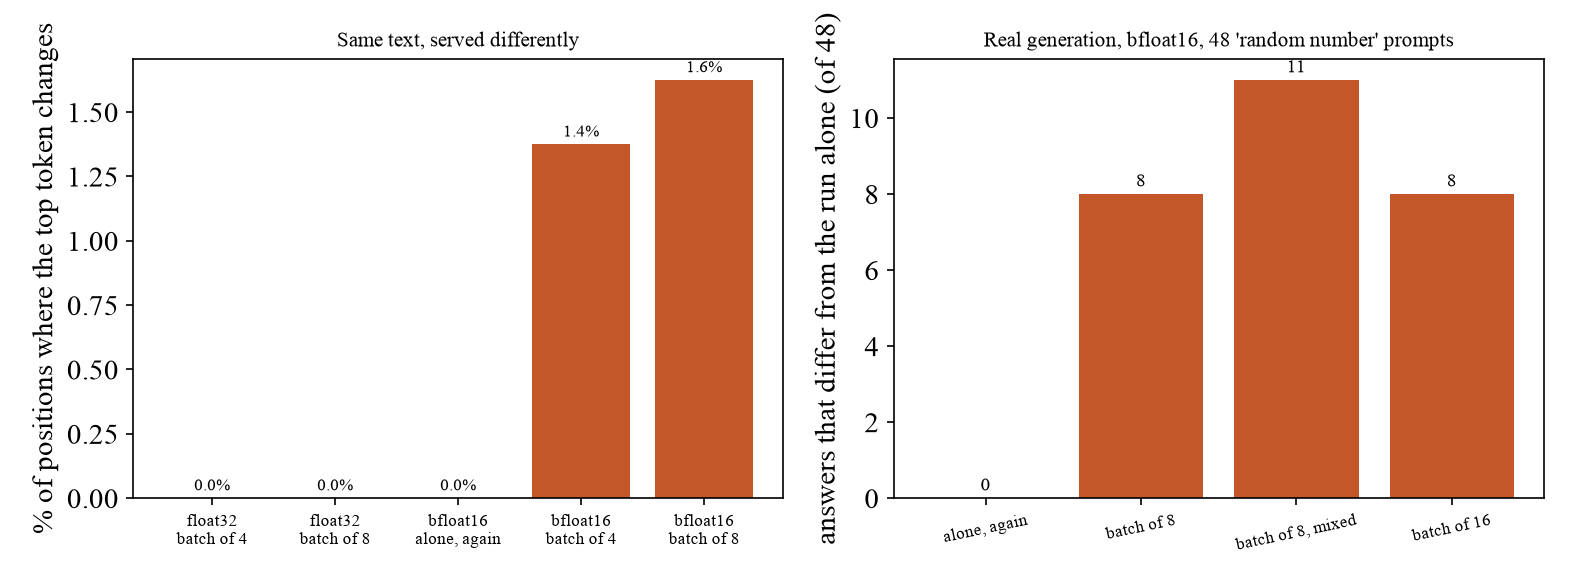

In [8]:
from IPython.display import Image, display
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
labels = [("float32", "batch of 4"), ("float32", "batch of 8"), ("bfloat16", "alone, again"), ("bfloat16", "batch of 4"), ("bfloat16", "batch of 8")]
vals = [100 * tf[k]["flips"] / tf[k]["positions"] for k in labels]
bars = ax[0].bar(range(len(labels)), vals, color=["#9aa5b1", "#9aa5b1", "#2b6f4e", "#c4572a", "#c4572a"])
ax[0].set_xticks(range(len(labels))); ax[0].set_xticklabels([f"{a}\n{b}" for a, b in labels], fontsize=8)
ax[0].set_ylabel("% of positions where the top token changes"); ax[0].set_title("Same text, served differently", fontsize=10)
for r, v in zip(bars, vals): ax[0].text(r.get_x() + r.get_width() / 2, v + 0.03, f"{v:.1f}%", ha="center", fontsize=8)
conds = ["alone, again", "batch of 8", "batch of 8, mixed", "batch of 16"]
ax[1].bar(range(len(conds)), [nd[c] for c in conds], color=["#2b6f4e", "#c4572a", "#c4572a", "#c4572a"])
ax[1].set_xticks(range(len(conds))); ax[1].set_xticklabels(conds, fontsize=8, rotation=12)
ax[1].set_ylabel("answers that differ from the run alone (of 48)"); ax[1].set_title("Real generation, bfloat16, 48 'random number' prompts", fontsize=10)
for k, c in enumerate(conds): ax[1].text(k, (nd[c]) + 0.2, str(nd[c]), ha="center", fontsize=9)
fig.tight_layout(); Path("figures").mkdir(exist_ok=True); fig.savefig("figures/16_batch_size_effect.png", dpi=150); plt.close(fig); display(Image(filename="figures/16_batch_size_effect.png"))

In the 16 open-ended prompts, repeating a request alone gave identical answers (0 of 16 differed), while 2 of 16 differed in batches of 4, 6 of 16 in batches of 8 and 1 of 16 in the mixed batch of 8; six prompts gave two or more distinct answers across the five ways of serving them. One example: "Name a random color" gave "Sapphire. Sapphire is a beautiful and rare color" alone and "Blue. I'm just a machine learning model," inside a batch of 8. The same batch size produced 6 differing answers in one arrangement and 1 in another (and 8 against 11 of 48 for the numbers, in the other direction), so which requests share the batch changes the outcome, as the post says for load. On the post's own prompt, 150 tokens in bfloat16, running alone again was identical and sharing a batch of 2 changed the answer from token 123 on, against token 103 in the post. That is one prompt, so read it as an illustration.

The graph's left panel is section 2 (top-token changes per position), the right panel is the 48-prompt test. None of this appeared in float32 on this CPU, in either test.

## 4. Keeping it from mattering

Three fixes, cheapest first. First, do not generate where a choice will do: read the scores of the eight route names in one forward pass and take the largest, as notebook 05 did. There is no word-by-word loop to diverge, but the scores still move in the last digits with the serving conditions, so a case whose top two scores are closer than that movement can flip. Second, escalate those cases: when the margin between the top two labels is smaller than the movement we saw, send the message to the slower tier or a person. Third, record the decision under a hash of everything that went into it and replay it: the same request then returns the recorded answer however it is served.

The post's own fix, batch-invariant kernels (the vLLM documentation lists a `VLLM_BATCH_INVARIANT=1` setting, in beta and for GPUs only, https://docs.vllm.ai/en/latest/features/batch_invariance/), makes the server's arithmetic independent of batch size; the post reports 26 s rising to 42 to 55 s for 1,000 requests on one GPU. It is a choice for the operator of the server, and a caller of a hosted API cannot make it. Nothing equivalent was tested here.

The closed choice below runs in bfloat16 on 16 Meridian test messages: each pass takes about 20 seconds on this CPU.

In [9]:
# Fix: read the scores of the eight route names in one forward pass and take the largest, as notebook 05 did. No sampling, no loop.
# Served in bfloat16, where the effect above is large, to test whether the fix holds. Sixteen messages: a bfloat16 pass takes tens of seconds here.
first_ids = [tok(r, add_special_tokens=False).input_ids[0] for r in ROUTES]
assert len(set(first_ids)) == 8, "the eight first tokens must be distinct"
def choose(model, texts):
    enc = tok([label_prompt(t) for t in texts], return_tensors="pt", padding=True)
    with torch.inference_mode():
        lg = model(**enc).logits[:, -1, :].float()           # left padding puts every prompt's last token at the end
    return torch.softmax(lg[:, first_ids], -1).numpy()
sel = te[::13][:16]                                  # every 13th test message: the file is sorted by label, so its first 16 messages are all one route
texts = [r["text"] for r in sel]
t0 = time.perf_counter()
ref_p = np.zeros((16, 8))
for i, t in enumerate(texts):
    ref_p[i] = choose(lm16, [t])[0]
    print(f"  reference {i + 1} of 16 ({time.perf_counter() - t0:.0f} s)", flush=True)
ref_lab = ref_p.argmax(1)
def margin(p): s = np.sort(p, 1); return s[:, -1] - s[:, -2]
conds = {"alone, again (first 4 messages)": [[0], [1], [2], [3]],
         "inside a batch of 4": [[0, 1, 2, 3], [4, 5, 6, 7], [8, 9, 10, 11], [12, 13, 14, 15]],
         "inside a batch of 8, mixed": [list(range(0, 16, 2)), list(range(1, 16, 2))]}
res_fix, flipped = {}, np.zeros(16, bool)
print(f"{'serving condition':36s}{'label flips':>14s}{'largest change in a probability':>34s}")
for cond, groups in conds.items():
    idx = [i for g in groups for i in g]
    P = np.zeros((16, 8))
    for g in groups: P[g] = choose(lm16, [texts[i] for i in g])
    fl = np.zeros(16, bool); fl[idx] = (P.argmax(1) != ref_lab)[idx]; flipped |= fl
    res_fix[cond] = {"messages": len(idx), "flips": int(fl.sum()), "max_prob_change": float(np.abs(P - ref_p)[idx].max())}
    print(f"{cond:36s}{int(fl.sum()):>9d} of {len(idx):<3d}{res_fix[cond]['max_prob_change']:>30.2e}", flush=True)
mg = margin(ref_p); dmax = max(v["max_prob_change"] for v in res_fix.values())
print(f"\nmargin between the top two labels (probability points): smallest {mg.min():.4f}, median {np.median(mg):.3f}")
print(f"accuracy of the closed choice on these 16 messages: {np.mean([ROUTES[l] == r['label'] for l, r in zip(ref_lab, sel)]):.2f}")
print(f"messages whose label changed under at least one serving condition: {int(flipped.sum())} of 16")
for k in (1, 2, 4):
    esc = mg < k * dmax
    print(f"escalate when the margin is below {k} x the largest change seen ({k * dmax:.4f}): {int(esc.sum())} of 16 messages escalated; changing labels left among those answered: {int((flipped & ~esc).sum())}")

  reference 1 of 16 (25 s)


  reference 2 of 16 (45 s)


  reference 3 of 16 (72 s)


  reference 4 of 16 (95 s)


  reference 5 of 16 (115 s)


...

serving condition                      label flips   largest change in a probability


alone, again (first 4 messages)             0 of 4                        0.00e+00


inside a batch of 4                         5 of 16                       1.17e-01


inside a batch of 8, mixed                  5 of 16                       1.16e-01



margin between the top two labels (probability points): smallest 0.0000, median 0.085
accuracy of the closed choice on these 16 messages: 0.38
messages whose label changed under at least one serving condition: 7 of 16
escalate when the margin is below 1 x the largest change seen (0.1174): 9 of 16 messages escalated; changing labels left among those answered: 0
escalate when the margin is below 2 x the largest change seen (0.2347): 10 of 16 messages escalated; changing labels left among those answered: 0
escalate when the margin is below 4 x the largest change seen (0.4695): 11 of 16 messages escalated; changing labels left among those answered: 0


Repeated alone, the 4 messages we repeated returned identical probabilities (largest change 0). Served inside a batch of 4, 5 of 16 labels flipped and one probability moved by up to 0.117; in a mixed batch of 8, 5 of 16 flipped (largest change 0.116); 7 of the 16 messages changed label under at least one condition. This model is near chance on these messages (6 of 16 correct, so no accuracy claim) and its margins are small (smallest 0.0000, median 0.085), which is why so many labels are borderline.

Escalating when the margin was below the largest change we saw (0.117) sent 9 of 16 messages to the slower tier and left no changing label among the 7 it answered; at 2 and at 4 times that threshold it sent 10 and 11 of 16. With 16 messages these are illustrations, not rates. The rule works as a filter, and with a model this uncertain it escalates most messages. A classifier with wider margins would escalate fewer, which we did not measure here.

In [10]:
# Fix: record the decision under a hash of everything that went into it, and replay it.
import hashlib
store = {}
def decide(text, model_id=NAME + "/bf16/closed-choice"):
    key = hashlib.sha256(json.dumps([model_id, sys_prompt, text]).encode()).hexdigest()
    if key not in store:
        store[key] = ROUTES[int(choose(lm16, [text]).argmax())]
    return store[key]
texts = texts[:6]
t0 = time.perf_counter(); first = [decide(t) for t in texts]; print(f"first pass: {len(texts)} model calls ({time.perf_counter() - t0:.0f} s)", flush=True)
t0 = time.perf_counter(); again = [decide(t) for t in texts]; dt = time.perf_counter() - t0
print(f"second pass: {sum(a == b for a, b in zip(first, again))} of {len(texts)} identical, {dt * 1000:.2f} ms for all {len(texts)} (lookups, no model call)")

first pass: 6 model calls (90 s)


second pass: 6 of 6 identical, 0.24 ms for all 6 (lookups, no model call)


The second pass returned all 6 recorded answers (6 of 6 identical, 0.24 ms in total, no model call). A cache fixes repeatability for requests it has seen: a new request, or the same request after the model or the prompt changes, is a new key and is decided again, so the cache is a record of past decisions and not a guarantee about future ones.

## 5. For contrast: what temperature does

Sampling above temperature 0 is the designed source of different answers, and the graph below measures how many. We ask the model to name the team for 20 Meridian messages, 10 samples per message at each of six temperatures, and count two things per message: the distinct team names after normalizing (labels) and the distinct raw replies (strings). The sampler is seeded (seed 0), and the numbers matched across the two sessions in which we ran this cell.

temperature 0.0: distinct labels per message 1.00, messages with 2+ distinct labels 0%, distinct strings 1.00, correct per sample 0.15


temperature 0.2: distinct labels per message 1.75, messages with 2+ distinct labels 55%, distinct strings 1.85, correct per sample 0.16


temperature 0.5: distinct labels per message 3.05, messages with 2+ distinct labels 90%, distinct strings 3.95, correct per sample 0.12


temperature 0.8: distinct labels per message 3.95, messages with 2+ distinct labels 100%, distinct strings 5.35, correct per sample 0.15


temperature 1.0: distinct labels per message 3.85, messages with 2+ distinct labels 95%, distinct strings 6.85, correct per sample 0.13


temperature 1.3: distinct labels per message 3.60, messages with 2+ distinct labels 95%, distinct strings 8.15, correct per sample 0.09
(846 s; 10 samples per message at each temperature above 0, 20 messages)


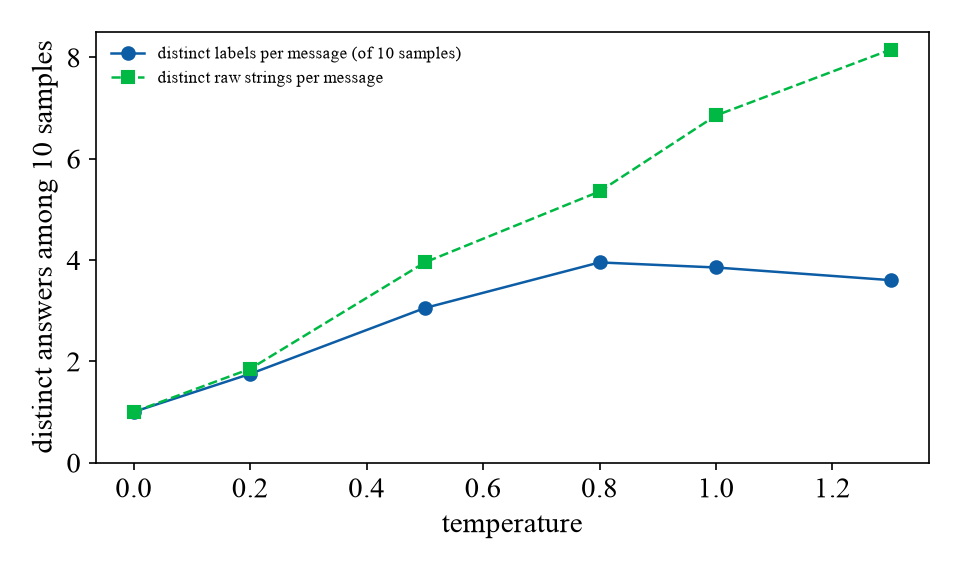

In [11]:
from IPython.display import Image, display
msgs = te[::10][:20]
TEMPS = [0.0, 0.2, 0.5, 0.8, 1.0, 1.3]
K = 10
rows = []
t0 = time.perf_counter()
torch.manual_seed(0)
for t in TEMPS:
    distinct_norm, distinct_raw, correct = [], [], []
    for r in msgs:
        p = label_prompt(r["text"])
        enc = tok([p], return_tensors="pt")
        with torch.inference_mode():
            if t == 0.0:
                out = lm.generate(**enc, max_new_tokens=8, do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
            else:
                out = lm.generate(**enc, max_new_tokens=8, do_sample=True, temperature=t, top_p=1.0, top_k=None, num_return_sequences=K, pad_token_id=tok.pad_token_id)
        texts = [tok.decode(o[enc.input_ids.shape[1]:], skip_special_tokens=True) for o in out]
        distinct_raw.append(len(set(texts))); distinct_norm.append(len({norm(x) for x in texts}))
        correct.append(np.mean([norm(x) == r["label"] for x in texts]))
    rows.append({"temperature": t, "mean_distinct_labels": float(np.mean(distinct_norm)), "share_with_disagreement": float(np.mean([d > 1 for d in distinct_norm])),
                 "mean_distinct_strings": float(np.mean(distinct_raw)), "mean_correct": float(np.mean(correct))})
    print(f"temperature {t:.1f}: distinct labels per message {rows[-1]['mean_distinct_labels']:.2f}, messages with 2+ distinct labels {rows[-1]['share_with_disagreement']:.0%}, distinct strings {rows[-1]['mean_distinct_strings']:.2f}, correct per sample {rows[-1]['mean_correct']:.2f}")
print(f"({time.perf_counter() - t0:.0f} s; {K} samples per message at each temperature above 0, {len(msgs)} messages)")
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot([r["temperature"] for r in rows], [r["mean_distinct_labels"] for r in rows], "o-", label="distinct labels per message (of 10 samples)")
ax.plot([r["temperature"] for r in rows], [r["mean_distinct_strings"] for r in rows], "s--", label="distinct raw strings per message")
ax.set_xlabel("temperature"); ax.set_ylabel("distinct answers among 10 samples"); ax.legend(frameon=False, fontsize=8); ax.set_ylim(0, None)
fig.tight_layout(); Path("figures").mkdir(exist_ok=True); fig.savefig("figures/16_temperature_vs_answers.png", dpi=150); plt.close(fig); display(Image(filename="figures/16_temperature_vs_answers.png"))

At temperature 0 every message gave 1 label and 1 string, in all 20 messages. At 0.2 the average was 1.75 labels per message and 55% of messages gave two or more labels; at 0.5, 3.05 labels and 90%; at 0.8, 3.95 labels and 100%. Above that the label count stopped rising (3.85 at 1.0, 3.60 at 1.3) while distinct raw strings kept climbing (6.85 at 1.0, 8.15 at 1.3). We did not check why the label count levels off; one guess is that more replies match no route name and fall into a single "unparseable" label. The accuracy per sample was 0.09 to 0.16, close to the 0.125 of a random pick among 8 routes, so this small model is not a good router and the count shows variability, not quality.

## What to take away

- **Repeatable for one way of serving, not across ways.** Run alone again, every answer was identical (0 of 48, 0 of 16 and 0 of 4 differed). Sharing a batch in half precision changed 8 to 11 of 48 short answers and 5 of 16 closed-choice labels; in full precision the top token never changed in 800 positions.
- **Test the way production serves.** A repeat test that sends one request at a time on a quiet machine passes and proves little. Serve the test requests inside batches, in different arrangements, and count the answers that change.
- **Make a decision repeatable by design.** Read a closed choice in one pass, escalate when the margin between the top two labels is smaller than the movement seen (0.117 here), and record each decision under a hash of everything that went into it.
- **Limits.** One 0.5-billion-parameter model on one CPU, 16 to 48 requests per test: illustrations without intervals. We measured no commercial API, we did not isolate where inside the model the change arises (the plain half-precision matrix product did not change with batch size on this CPU), and the post's 80 answers in 1,000 runs are for a 235B model on a GPU server.

The numbers in this notebook are saved in `data/results/16_same_question_different_answer.json`, assembled from the printed output of the two sessions in which the cells ran.